# Random forest regression

This notebook evaluates an initial random forest baseline with the project's shared development/test split, five-fold cross-validation, and repeated model seeds.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# Make the shared project code accessible.
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import FEATURE_COLUMNS, RF_SEEDS, TARGET_COLUMNS
from src.data import create_dev_test_split, load_data
from src.evaluation import get_cv, regression_metrics

df = load_data()
X_dev, X_test, y_dev, y_test = create_dev_test_split(df)

print("Dataset shape:", df.shape)
print("Development features:", X_dev.shape)
print("Development targets:", y_dev.shape)
print("Held-out test features:", X_test.shape)
print("Held-out test targets:", y_test.shape)

Dataset shape: (768, 10)
Development features: (614, 8)
Development targets: (614, 2)
Held-out test features: (154, 8)
Held-out test targets: (154, 2)


## Shared cross-validation folds

The held-out test set remains unused. Every development observation appears in validation exactly once during each five-fold cross-validation pass.

In [2]:
folds = list(get_cv().split(X_dev))

for fold, (train_idx, val_idx) in enumerate(folds, start=1):
    print(
        f"Fold {fold}: "
        f"{len(train_idx)} training, "
        f"{len(val_idx)} validation"
    )

Fold 1: 491 training, 123 validation
Fold 2: 491 training, 123 validation
Fold 3: 491 training, 123 validation
Fold 4: 491 training, 123 validation
Fold 5: 492 training, 122 validation


## Initial random forest baseline

A fresh 100-tree model is fit for every target, fold, and declared random-forest seed. This keeps the data partitions consistent with the linear and ridge experiments while also measuring random-forest initialization variability.

In [3]:
rf_results = []
oof_predictions = []
plot_seed = RF_SEEDS[0]

for target in TARGET_COLUMNS:
    for model_seed in RF_SEEDS:
        for fold, (train_idx, val_idx) in enumerate(folds, start=1):
            X_train = X_dev.iloc[train_idx]
            X_val = X_dev.iloc[val_idx]
            y_train = y_dev[target].iloc[train_idx]
            y_val = y_dev[target].iloc[val_idx]

            model = RandomForestRegressor(
                n_estimators=100,
                random_state=model_seed,
                n_jobs=-1,
            )

            start = perf_counter()
            model.fit(X_train, y_train)
            train_time = perf_counter() - start

            start = perf_counter()
            predictions = model.predict(X_val)
            prediction_time = perf_counter() - start

            metrics = regression_metrics(y_val, predictions)
            rf_results.append({
                "target": target,
                "model": "random_forest",
                "n_features": len(FEATURE_COLUMNS),
                "fold": fold,
                "model_seed": model_seed,
                **metrics,
                "train_time": train_time,
                "prediction_time": prediction_time,
            })

            if model_seed == plot_seed:
                oof_predictions.append(pd.DataFrame({
                    "row_index": y_val.index,
                    "target": target,
                    "fold": fold,
                    "actual": y_val.to_numpy(),
                    "predicted": predictions,
                }))

rf_results_df = pd.DataFrame(rf_results)
oof_predictions_df = pd.concat(oof_predictions, ignore_index=True)

expected_rows = len(TARGET_COLUMNS) * len(RF_SEEDS) * len(folds)
assert len(rf_results_df) == expected_rows
assert (
    oof_predictions_df.groupby("target")["row_index"].nunique()
    == len(X_dev)
).all()

print(f"Recorded {len(rf_results_df)} fold-level evaluations.")
rf_results_df.head()

Recorded 50 fold-level evaluations.


,target,model,n_features,fold,model_seed,mae,rmse,r2,train_time,prediction_time
0,heating_load,random_forest,8,1,0,0.328074,0.527792,0.997439,0.364429,0.062497
1,heating_load,random_forest,8,2,0,0.318261,0.478310,0.997755,0.207007,0.119478
2,heating_load,random_forest,8,3,0,0.344156,0.533009,0.997126,0.291383,0.070965
3,heating_load,random_forest,8,4,0,0.388612,0.550209,0.997007,0.214254,0.061876
4,heating_load,random_forest,8,5,0,0.342972,0.513523,0.997092,0.241893,0.071889


## Cross-validation summary

The table summarizes performance across all five folds and five model seeds. The saved fold-level table retains both sources of variation for later comparisons.

In [4]:
rf_summary_df = (
    rf_results_df
    .groupby(["target", "model", "n_features"], as_index=False)
    .agg(
        mae_mean=("mae", "mean"),
        mae_std=("mae", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        r2_mean=("r2", "mean"),
        r2_std=("r2", "std"),
        train_time_mean=("train_time", "mean"),
        prediction_time_mean=("prediction_time", "mean"),
    )
)

rf_summary_df.round(4)

,target,model,n_features,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std,train_time_mean,prediction_time_mean
0,cooling_load,random_forest,8,1.0322,0.1136,1.7226,0.1664,0.9666,0.0047,0.1935,0.0586
1,heating_load,random_forest,8,0.3443,0.0257,0.5182,0.0253,0.9973,0.0003,0.2197,0.0662


## Out-of-fold predictions

These plots use seed 0 and combine the validation predictions from all five folds, so every development observation is represented without being predicted by a model that trained on it.

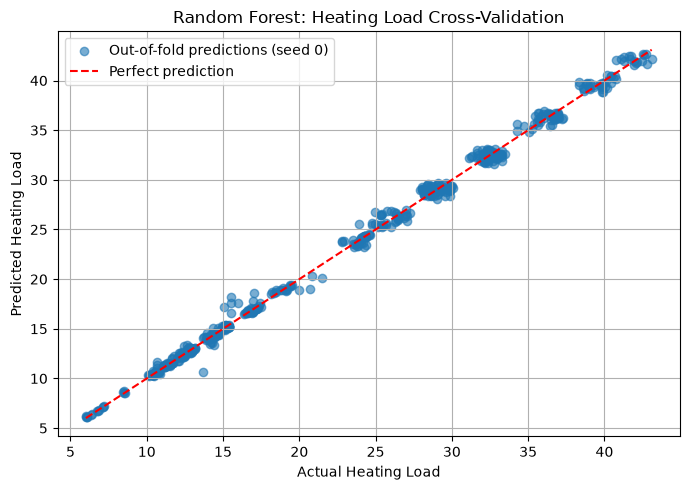

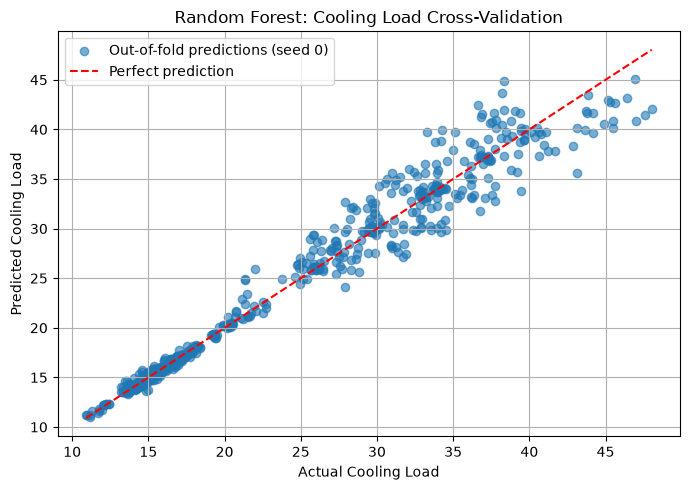

Saved fold-level results to results\tables\random_forest_baseline_cv.csv


In [5]:
figures_dir = project_root / "results" / "figures"
tables_dir = project_root / "results" / "tables"
figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

results_path = tables_dir / "random_forest_baseline_cv.csv"
rf_results_df.to_csv(results_path, index=False)

for target in TARGET_COLUMNS:
    target_predictions = oof_predictions_df.query("target == @target")
    display_name = target.replace("_", " ").title()

    minimum = min(
        target_predictions["actual"].min(),
        target_predictions["predicted"].min(),
    )
    maximum = max(
        target_predictions["actual"].max(),
        target_predictions["predicted"].max(),
    )

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        target_predictions["actual"],
        target_predictions["predicted"],
        alpha=0.6,
        label=f"Out-of-fold predictions (seed {plot_seed})",
    )
    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        "r--",
        label="Perfect prediction",
    )
    ax.set(
        xlabel=f"Actual {display_name}",
        ylabel=f"Predicted {display_name}",
        title=f"Random Forest: {display_name} Cross-Validation",
    )
    ax.legend()
    ax.grid(True)
    fig.tight_layout()
    fig.savefig(
        figures_dir / f"random_forest_{target}_cv.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

print(f"Saved fold-level results to {results_path.relative_to(project_root)}")